# **Funnel Analysis on Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as datetime
import plotly.express as px
import plotly.graph_objects as go
import plotly.subplots as make_subplots

In [2]:
# Styling

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

# Dataset Exploration

In [3]:
df = pd.read_csv(r'C:\Users\ankus\OneDrive\Desktop\SDE+DATA\DATA\Projects\Funnel_Mechanism (Python_PowerBI)\funnel_data.csv')

In [4]:
df.head()

,User_id,Session_id,Event,Timestamp,Device,Region,Channel,Category,Revenue,Bounce_flag
0,USR00001,SES00001,Browse,31-01-2026 05:27,Tablet,North,Google Ads,Fashion,0.0,Yes
1,USR00001,SES00001,Add to Cart,31-01-2026 05:32,Desktop,South,Email,Fashion,0.0,Yes
2,USR00002,SES00002,Browse,30-01-2026 04:36,Mobile,West,Social Media,Sports,0.0,Yes
3,USR00003,SES00003,Browse,20-01-2026 06:20,Mobile,West,Organic,Electronics,0.0,No
4,USR00003,SES00003,Add to Cart,20-01-2026 06:22,Desktop,East,Social Media,Electronics,0.0,No


In [5]:
df.tail()

,User_id,Session_id,Event,Timestamp,Device,Region,Channel,Category,Revenue,Bounce_flag
21498,USR09998,SES09998,Browse,11-01-2026 22:30,Desktop,North,Social Media,Beauty,0.0,Yes
21499,USR09998,SES09998,Add to Cart,11-01-2026 22:33,Desktop,North,Social Media,Home,0.0,Yes
21500,USR09999,SES09999,Browse,15-01-2026 21:56,Desktop,East,Email,Fashion,0.0,Yes
21501,USR10000,SES10000,Browse,15-01-2026 21:28,Tablet,West,Google Ads,Electronics,0.0,Yes
21502,USR10000,SES10000,Add to Cart,15-01-2026 21:32,Tablet,East,Organic,Beauty,0.0,Yes


In [6]:
df.sample(5)

,User_id,Session_id,Event,Timestamp,Device,Region,Channel,Category,Revenue,Bounce_flag
15610,USR07299,SES07299,Add to Cart,19-01-2026 21:04,Mobile,North,Social Media,Beauty,0.0,Yes
17926,USR08378,SES08378,Add to Cart,01-02-2026 21:50,Tablet,West,Organic,Fashion,0.0,Yes
17768,USR08303,SES08303,Browse,12-01-2026 03:40,Desktop,West,Email,Sports,0.0,Yes
2581,USR01205,SES01205,Browse,12-01-2026 19:22,Desktop,West,Google Ads,Electronics,0.0,Yes
20864,USR09714,SES09714,Add to Cart,29-01-2026 13:16,Desktop,South,Google Ads,Sports,0.0,No


In [7]:
df.columns

Index(['User_id', 'Session_id', 'Event', 'Timestamp', 'Device', 'Region',
       'Channel', 'Category', 'Revenue', 'Bounce_flag'],
      dtype='object')

In [8]:
type(df)

pandas.core.frame.DataFrame

In [9]:
df.dtypes

User_id         object
Session_id      object
Event           object
Timestamp       object
Device          object
Region          object
Channel         object
Category        object
Revenue        float64
Bounce_flag     object
dtype: object

In [10]:
# changing timestamp to datetime format
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\1068629539.py:2: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Timestamp'] = pd.to_datetime(df['Timestamp'])


In [11]:
df.dtypes

User_id                object
Session_id             object
Event                  object
Timestamp      datetime64[ns]
Device                 object
Region                 object
Channel                object
Category               object
Revenue               float64
Bounce_flag            object
dtype: object

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21503 entries, 0 to 21502
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   User_id      21503 non-null  object        
 1   Session_id   21503 non-null  object        
 2   Event        21503 non-null  object        
 3   Timestamp    21503 non-null  datetime64[ns]
 4   Device       21503 non-null  object        
 5   Region       21503 non-null  object        
 6   Channel      21503 non-null  object        
 7   Category     21503 non-null  object        
 8   Revenue      21503 non-null  float64       
 9   Bounce_flag  21503 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(8)
memory usage: 1.6+ MB


In [13]:
df.describe()

,Timestamp,Revenue
count,21503,21503.00000
mean,2026-01-20 20:59:45.914523392,55.77670
min,2026-01-05 19:57:00,0.00000
25%,2026-01-13 11:17:00,0.00000
50%,2026-01-20 19:44:00,0.00000
75%,2026-01-28 08:14:00,0.00000
max,2026-02-04 19:55:00,1997.91000
std,NaN,268.57677


In [14]:
df.describe(include= 'all')

,User_id,Session_id,Event,Timestamp,Device,Region,Channel,Category,Revenue,Bounce_flag
count,21503,21503,21503,21503,21503,21503,21503,21503,21503.00000,21503
unique,10000,10000,4,NaN,3,4,4,5,NaN,2
top,USR05856,SES05856,Browse,NaN,Mobile,West,Social Media,Beauty,NaN,Yes
freq,4,4,10000,NaN,7303,5489,5460,4324,NaN,17179
mean,NaN,NaN,NaN,2026-01-20 20:59:45.914523392,NaN,NaN,NaN,NaN,55.77670,NaN
min,NaN,NaN,NaN,2026-01-05 19:57:00,NaN,NaN,NaN,NaN,0.00000,NaN
25%,NaN,NaN,NaN,2026-01-13 11:17:00,NaN,NaN,NaN,NaN,0.00000,NaN
50%,NaN,NaN,NaN,2026-01-20 19:44:00,NaN,NaN,NaN,NaN,0.00000,NaN
75%,NaN,NaN,NaN,2026-01-28 08:14:00,NaN,NaN,NaN,NaN,0.00000,NaN
max,NaN,NaN,NaN,2026-02-04 19:55:00,NaN,NaN,NaN,NaN,1997.91000,NaN


In [15]:
df.shape

(21503, 10)

# Data Cleaning

In [16]:
print(df['User_id'].isnull().sum())
print(df['Event'].isnull().sum())
print(df['Session_id'].isnull().sum())
print(df['Timestamp'].isnull().sum())
print(df['Device'].isnull().sum())
print(df['Region'].isnull().sum())
print(df['Channel'].isnull().sum())
print(df['Category'].isnull().sum())
print(df['Revenue'].isnull().sum())
print(df['Bounce_flag'].isnull().sum())

0
0
0
0
0
0
0
0
0
0


In [17]:
df['Date'] = df['Timestamp'].dt.date
df['Day_of_week'] = df['Timestamp'].dt.day_name()
df['Hour'] = df['Timestamp'].dt.hour
df['WeekNumber'] = df['Timestamp'].dt.isocalendar().week

In [18]:
df.head()

,User_id,Session_id,Event,Timestamp,Device,Region,Channel,Category,Revenue,Bounce_flag,Date,Day_of_week,Hour,WeekNumber
0,USR00001,SES00001,Browse,2026-01-31 05:27:00,Tablet,North,Google Ads,Fashion,0.0,Yes,2026-01-31,Saturday,5,5
1,USR00001,SES00001,Add to Cart,2026-01-31 05:32:00,Desktop,South,Email,Fashion,0.0,Yes,2026-01-31,Saturday,5,5
2,USR00002,SES00002,Browse,2026-01-30 04:36:00,Mobile,West,Social Media,Sports,0.0,Yes,2026-01-30,Friday,4,5
3,USR00003,SES00003,Browse,2026-01-20 06:20:00,Mobile,West,Organic,Electronics,0.0,No,2026-01-20,Tuesday,6,4
4,USR00003,SES00003,Add to Cart,2026-01-20 06:22:00,Desktop,East,Social Media,Electronics,0.0,No,2026-01-20,Tuesday,6,4


In [19]:
df['Event_sequence'] = df.groupby('Session_id').cumcount() + 1

In [20]:
df.head()

,User_id,Session_id,Event,Timestamp,Device,Region,Channel,Category,Revenue,Bounce_flag,Date,Day_of_week,Hour,WeekNumber,Event_sequence
0,USR00001,SES00001,Browse,2026-01-31 05:27:00,Tablet,North,Google Ads,Fashion,0.0,Yes,2026-01-31,Saturday,5,5,1
1,USR00001,SES00001,Add to Cart,2026-01-31 05:32:00,Desktop,South,Email,Fashion,0.0,Yes,2026-01-31,Saturday,5,5,2
2,USR00002,SES00002,Browse,2026-01-30 04:36:00,Mobile,West,Social Media,Sports,0.0,Yes,2026-01-30,Friday,4,5,1
3,USR00003,SES00003,Browse,2026-01-20 06:20:00,Mobile,West,Organic,Electronics,0.0,No,2026-01-20,Tuesday,6,4,1
4,USR00003,SES00003,Add to Cart,2026-01-20 06:22:00,Desktop,East,Social Media,Electronics,0.0,No,2026-01-20,Tuesday,6,4,2


In [21]:
print(f'Date Range: {df["Date"].min()} to {df["Date"].max()}')

Date Range: 2026-01-05 to 2026-02-04


#  Funnel Stage Definition and Aggergation

In [22]:
funnel_stages = ['Browse', 'Add to Cart', 'Checkout', 'Purchase']

session_summary = df.groupby('Session_id').agg({
    'User_id': 'first',
    'Timestamp': ['min', 'max'],
    'Event': lambda x: list(x),
    'Device': 'first',
    'Region': 'first',
    'Channel': 'first',
    'Category': 'first',
    'Revenue': 'max',
    'Bounce_flag': 'first'
}).reset_index()

session_summary.columns = ['Session_id', 'User_id', 'Session_start', 'Session_end', 'Event_Sequence', 'Device', 'Region', 'Channel', 'Category', 'Revenue', 'Bounce_flag']    

session_summary['Session_duration_min']=(
    session_summary['Session_end'] - session_summary['Session_start']
).dt.total_seconds() / 60


def get_max_funnel_stage(events):
    stage_values={stage: i for i, stage in enumerate(funnel_stages)}
    max_stage_index = -1
    for event in events:
        if event in stage_values and stage_values[event] > max_stage_index:
            max_stage_index = stage_values[event]
    return funnel_stages[max_stage_index] if max_stage_index != -1 else 'Browse'
    
session_summary['Max_Funnel_Stage'] = session_summary['Event_Sequence'].apply(get_max_funnel_stage)
session_summary.head()

,Session_id,User_id,Session_start,Session_end,Event_Sequence,Device,Region,Channel,Category,Revenue,Bounce_flag,Session_duration_min,Max_Funnel_Stage
0,SES00001,USR00001,2026-01-31 05:27:00,2026-01-31 05:32:00,"[Browse, Add to Cart]",Tablet,North,Google Ads,Fashion,0.0,Yes,5.0,Add to Cart
1,SES00002,USR00002,2026-01-30 04:36:00,2026-01-30 04:36:00,[Browse],Mobile,West,Social Media,Sports,0.0,Yes,0.0,Browse
2,SES00003,USR00003,2026-01-20 06:20:00,2026-01-20 06:28:00,"[Browse, Add to Cart, Checkout, Purchase]",Mobile,West,Organic,Electronics,594.8,No,8.0,Purchase
3,SES00004,USR00004,2026-01-12 17:29:00,2026-01-12 17:33:00,"[Browse, Add to Cart, Checkout]",Tablet,East,Google Ads,Electronics,0.0,Yes,4.0,Checkout
4,SES00005,USR00005,2026-01-23 04:07:00,2026-01-23 04:10:00,"[Browse, Add to Cart]",Tablet,North,Social Media,Sports,0.0,Yes,3.0,Add to Cart


# Overall Funnel Analysis

In [29]:
funnel_metrics = []

for i, stage in enumerate(funnel_stages):
    if i == 0:
        count = len(session_summary)
    else:
        count = len(session_summary[session_summary['Max_Funnel_Stage'].isin(funnel_stages[i:])])

    funnel_metrics.append({
        'Stage': stage,
        'Sessions': count,
        'Stage_order': i
    })

funnel_df = pd.DataFrame(funnel_metrics)


funnel_df['Conversion_Rate'] = (funnel_df['Sessions'] / funnel_df['Sessions'].iloc[0] * 100).round(2)
funnel_df['Drop_off_rate'] = (1-funnel_df['Sessions'] / funnel_df['Sessions'].shift(1)) * 100
funnel_df['Drop_off_rate'].iloc[0] = 0
funnel_df['Drop_off_rate'] = funnel_df['Drop_off_rate'].round(2)

print(funnel_df)

# Revenue Analysis at Purchase Stage

revenue_stats = session_summary[session_summary['Max_Funnel_Stage'] == 'Purchase'].agg({
    'Revenue': ['sum', 'mean', 'count']
}).round(2)

print("\n Revenue Analysis: ")
print(f"Total Revenue: ${revenue_stats.iloc[0,0]:,.2f}")
print(f"Average Order Value: ${revenue_stats.iloc[1,0]:,.2f}")
print(f"Total Orders: {revenue_stats.iloc[2,0]:,}")

         Stage  Sessions  Stage_order  Conversion_Rate  Drop_off_rate
0       Browse     10000            0           100.00           0.00
1  Add to Cart      6996            1            69.96          30.04
2     Checkout      3426            2            34.26          51.03
3     Purchase      1081            3            10.81          68.45

 Revenue Analysis: 
Total Revenue: $1,199,366.38
Average Order Value: $1,109.50
Total Orders: 1,081.0


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\2703606784.py:20: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  funnel_df['Drop_off_rate'].iloc[0] = 0
C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\2703606784.py:20: SettingWithCopyWarni

# Visualization

# 1.Overall Funnel

In [32]:
fig = make_subplots.make_subplots(
    rows=2, cols=2,
    subplot_titles=("Funnel Conversion Rates", "Stage-to-Stage Drop-off",
                    "Revenue by Funnel Stage", "Session Duration by Stage"),
    specs=[[{"secondary_y": False}, {"secondary_y": False}],
           [{"secondary_y": False}, {"secondary_y": False}]]
)

# Conversion Rates Bar Chart
fig.add_trace(
    go.Bar(
        x=funnel_df['Stage'],
        y=funnel_df['Sessions'],
        text=funnel_df['Sessions'],
        textposition='auto',
        name="Sessions",
        marker_color='lightsalmon'
    ),
    row=1, col=1
)

# Drop-off Rates scatter plot
fig.add_trace(
    go.Scatter(
        x=funnel_df['Stage'],
        y=funnel_df['Drop_off_rate'],
        mode='lines+markers+text',
        text=funnel_df['Drop_off_rate'],
        textposition='top center',
        name="Drop-off Rate (%)",
        line=dict(color='firebrick', width=3)
    ),
    row=1, col=2, secondary_y=False
)

# Revenue by Funnel Stage Bar Chart
revenue_by_stage = session_summary.groupby('Max_Funnel_Stage')['Revenue'].sum().reset_index()
fig.add_trace(
    go.Bar(
        x=revenue_by_stage['Max_Funnel_Stage'],
        y=revenue_by_stage['Revenue'],
        text=[f'${x:,.0f}' for x in revenue_by_stage['Revenue']],
        textposition='auto',
        name="Revenue",
        marker_color='lightseagreen'
    ),
    row=2, col=1
)

# Session Duration by Stage Bar Chart
duration_by_stage = session_summary.groupby('Max_Funnel_Stage')['Session_duration_min'].mean().reset_index()
fig.add_trace(
    go.Bar(
        x=duration_by_stage['Max_Funnel_Stage'],
        y=duration_by_stage['Session_duration_min'],
        text=duration_by_stage['Session_duration_min'].round(2),
        textposition='auto',
        name="Avg Session Duration (min)",
        marker_color='mediumpurple'
    ),
    row=2, col=2
)

fig.update_layout(
    title_text="E-commerce Funnel Analysis",
    height=800,
    showlegend=False
)
fig.show()

# 2. Channel Performance Analysis

Channel Performance Analysis: 


,Channel,Total_Sessions,Browse_Sessions,Browse_Rate,Add to Cart_Sessions,Add to Cart_Rate,Checkout_Sessions,Checkout_Rate,Purchase_Sessions,Purchase_Rate,Total_Revenue,AOV,Conversion_Rate
0,Google Ads,2437,2437,100.0,1700,69.76,811,33.28,261,10.71,288047.57,1103.63,10.71
1,Email,2478,2478,100.0,1743,70.34,871,35.15,280,11.30,309470.24,1105.25,11.30
2,Social Media,2558,2558,100.0,1806,70.60,896,35.03,278,10.87,311782.71,1121.52,10.87
3,Organic,2527,2527,100.0,1747,69.13,848,33.56,262,10.37,290065.86,1107.12,10.37


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\1321244615.py:37: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\1321244615.py:50: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\1321244615.py:63: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




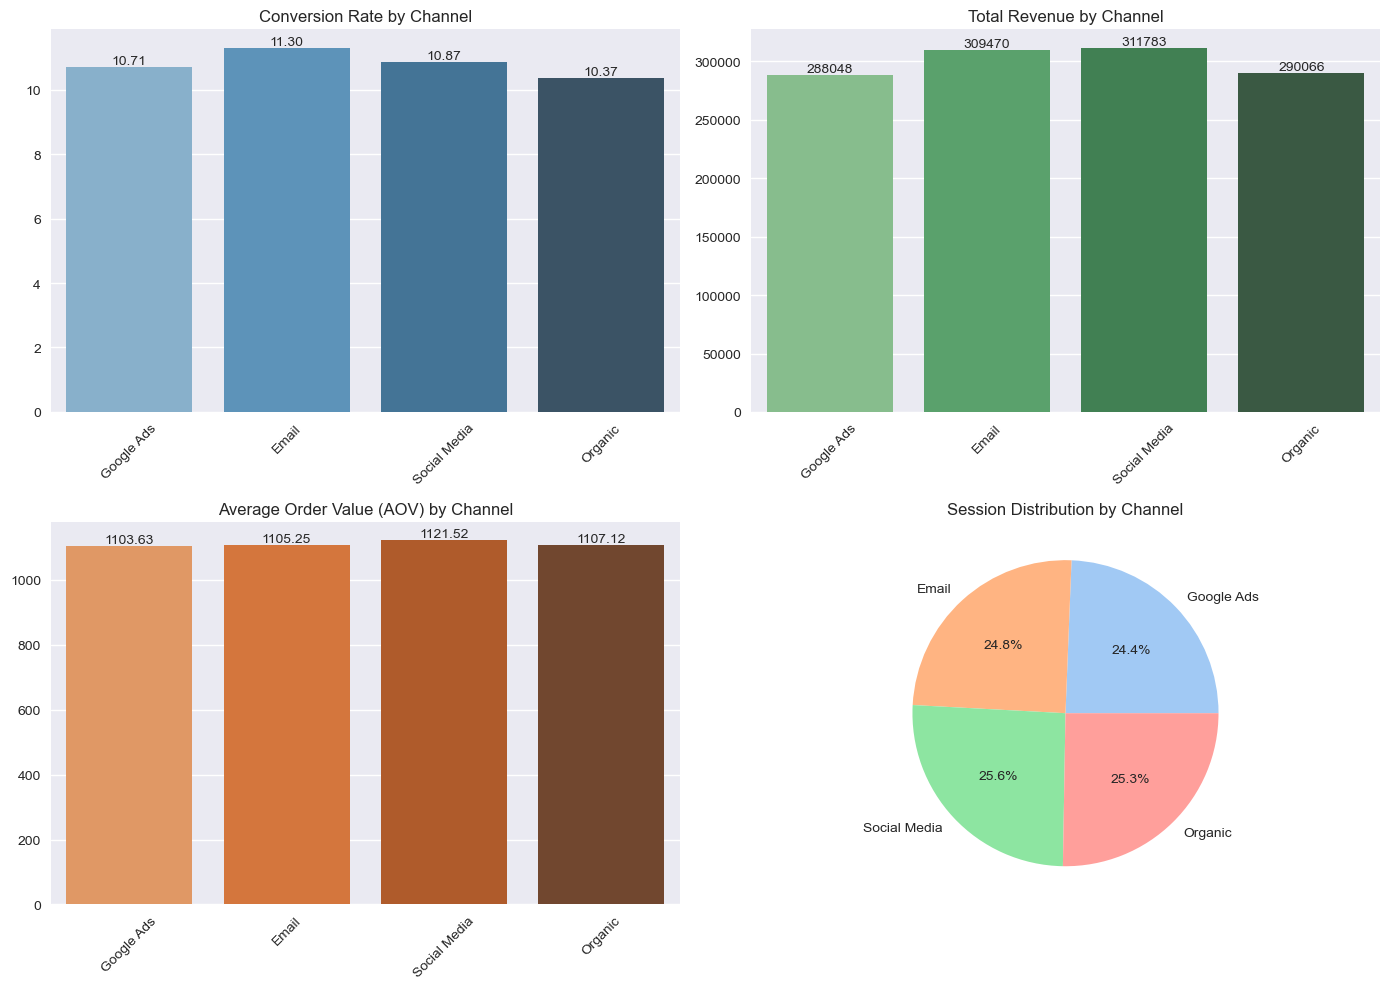

In [39]:
channel_funnel = []

for channel in df['Channel'].unique():
    channel_sessions = session_summary[session_summary['Channel'] == channel]
    total_sessions = len(channel_sessions)

    if total_sessions > 0:
        channel_metrics={"Channel": channel, "Total_Sessions": total_sessions}

        for i, stage in enumerate(funnel_stages):
            if i == 0:
                count = total_sessions
            else:
                count = len(channel_sessions[channel_sessions['Max_Funnel_Stage'].isin(funnel_stages[i:])])

            channel_metrics[f'{stage}_Sessions'] = count
            channel_metrics[f'{stage}_Rate'] = (count / total_sessions * 100)
        

        purchase_sessions = channel_sessions[channel_sessions['Max_Funnel_Stage'] == 'Purchase']
        channel_metrics['Total_Revenue'] = purchase_sessions['Revenue'].sum()
        channel_metrics['AOV'] = purchase_sessions['Revenue'].mean() if len(purchase_sessions) > 0 else 0
        channel_metrics['Conversion_Rate'] = (len(purchase_sessions) / total_sessions * 100)

        channel_funnel.append(channel_metrics)


channel_df = pd.DataFrame(channel_funnel)

print("Channel Performance Analysis: ")
display(channel_df.round(2))

# Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Conversion rate by channel
sns.barplot(data=channel_df, x='Channel', y='Conversion_Rate', ax=ax1, palette='Blues_d')
ax1.set_title('Conversion Rate by Channel')
ax1.tick_params(axis='x', rotation=45)
ax1.set_xlabel('')
ax1.set_ylabel('')

for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.2f}',
                 (p.get_x() + p.get_width()/2, p.get_height()),
                 ha='center', va='bottom')


# Total Revenue by channel
sns.barplot(data=channel_df, x='Channel', y='Total_Revenue', ax=ax2, palette='Greens_d')
ax2.set_title('Total Revenue by Channel')
ax2.tick_params(axis='x', rotation=45)
ax2.set_xlabel('')
ax2.set_ylabel('')

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.0f}',
                 (p.get_x() + p.get_width()/2, p.get_height()),
                 ha='center', va='bottom')


# AOV by Channel
sns.barplot(data=channel_df, x='Channel', y='AOV', ax=ax3, palette='Oranges_d')
ax3.set_title('Average Order Value (AOV) by Channel')
ax3.tick_params(axis='x', rotation=45)
ax3.set_xlabel('')
ax3.set_ylabel('')

for p in ax3.patches:
    ax3.annotate(f'{p.get_height():.2f}',
                 (p.get_x() + p.get_width()/2, p.get_height()),
                 ha='center', va='bottom')


# Session distribution by channel
channel_df['Session_percentage']= (channel_df['Total_Sessions'] / channel_df['Total_Sessions'].sum()) * 100
ax4.pie(channel_df['Session_percentage'],
        labels=channel_df['Channel'],
        autopct='%1.1f%%',
        colors=sns.color_palette('pastel'))

ax4.set_title('Session Distribution by Channel')

plt.tight_layout()
plt.show()


# Regional Analysis

Regional Performance Analysis: 


,Total_Sessions,Total_Revenue,Session_duration_min,Converted_Sessions,Conversion_Rate,AOV
Region,,,,,,
East,2479,296045.97,4.016942,268,10.81,1104.65
North,2478,292322.73,4.028249,264,10.65,1107.28
South,2453,279566.53,3.933958,256,10.44,1092.06
West,2590,331431.15,4.131274,293,11.31,1131.16


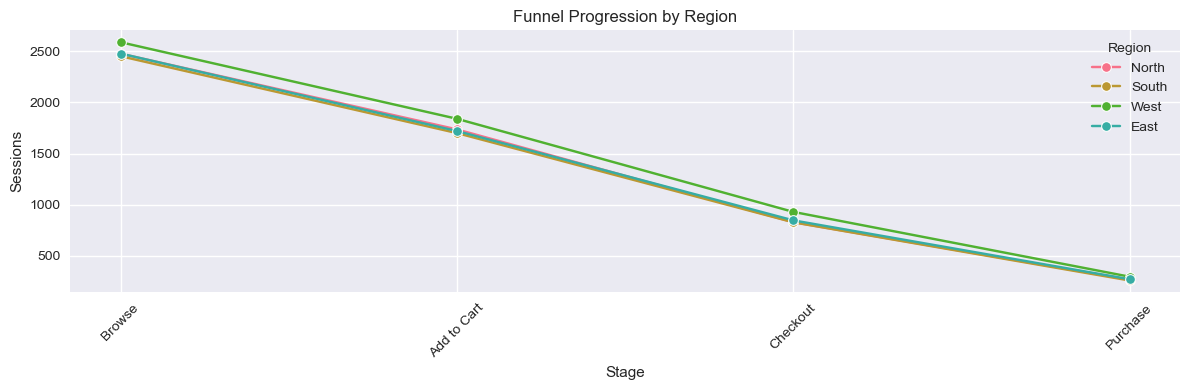

In [42]:
regional_analysis = session_summary.groupby('Region').agg({
    'Session_id': 'count',
    'Revenue': 'sum',
    'Session_duration_min': 'mean'
}).rename(columns={
    'Session_id': 'Total_Sessions',
    'Revenue': 'Total_Revenue',})

# Conversion rate by region

regional_conversion = session_summary[session_summary['Max_Funnel_Stage'] == 'Purchase'].groupby('Region').size()
regional_analysis['Converted_Sessions'] = regional_conversion
regional_analysis['Conversion_Rate'] = (regional_analysis['Converted_Sessions'] / regional_analysis['Total_Sessions'] * 100).round(2)
regional_analysis['AOV'] = (regional_analysis['Total_Revenue'] / regional_analysis['Converted_Sessions']).round(2)

print("Regional Performance Analysis: ")
display(regional_analysis)

# Visualization
regional_funnel_data = []
for region in df['Region'].unique():
    region_sessions = session_summary[session_summary['Region'] == region]
    for stage in funnel_stages:
        if stage == 'Browse':
            count = len(region_sessions)
        else:
            count = len(region_sessions[region_sessions['Max_Funnel_Stage'].isin(funnel_stages[funnel_stages.index(stage):])])
        regional_funnel_data.append({
            'Region': region,
            'Stage': stage,
            'Sessions': count
        })

regional_funnel_df = pd.DataFrame(regional_funnel_data)


plt.figure(figsize=(12, 4))
sns.lineplot(data=regional_funnel_df, x='Stage', y='Sessions', hue='Region', marker='o')
plt.title('Funnel Progression by Region')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Device and Product Category Analysis

Device Performance Analysis: 


,Total_Sessions,Revenue,Session_duration_min,Purchases,Conversion_Rate,AOV
Device,,,,,,
Desktop,3273,397844.28,4.048579,355,10.85,1120.69
Mobile,3382,373540.44,3.997635,347,10.26,1076.49
Tablet,3345,427981.66,4.041555,379,11.33,1129.24


Product Category Performance Analysis: 


,Total_Sessions,Revenue,Purchases,Conversion_Rate,AOV,Revenue_per_session
Category,,,,,,
Beauty,2025,239278.60,206,10.17,1161.55,118.16
Electronics,1992,272002.51,242,12.15,1123.98,136.55
Fashion,2008,235575.52,219,10.91,1075.69,117.32
Home,2015,217838.54,199,9.88,1094.67,108.11
Sports,1960,234671.21,215,10.97,1091.49,119.73


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\907653937.py:36: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\907653937.py:40: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




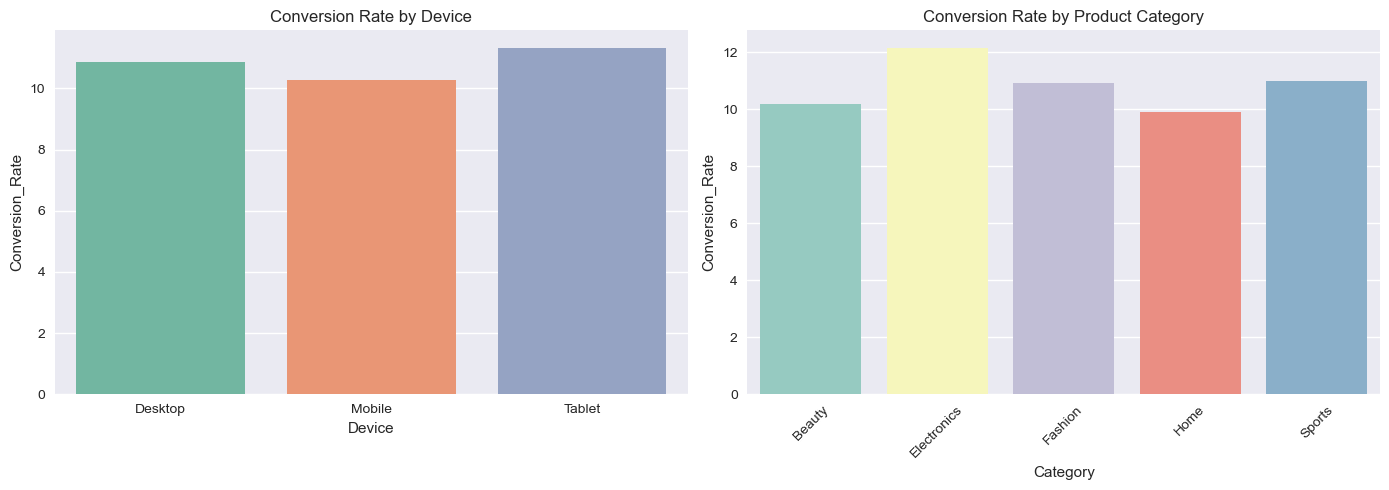

In [45]:
device_analysis = session_summary.groupby('Device').agg({
    'Session_id': 'count',
    'Revenue': 'sum',
    'Session_duration_min': 'mean',
    'Max_Funnel_Stage': lambda x: (x=='Purchase').sum()
}).rename(columns={
    'Session_id': 'Total_Sessions',
    'Max_Funnel_Stage': 'Purchases',})

device_analysis['Conversion_Rate'] = (device_analysis['Purchases'] / device_analysis['Total_Sessions'] * 100).round(2)
device_analysis['AOV'] = (device_analysis['Revenue'] / device_analysis['Purchases']).round(2)

print("Device Performance Analysis: ")
display(device_analysis)

# Product Category Analysis
product_analysis = session_summary.groupby('Category').agg({
    'Session_id': 'count',
    'Revenue': 'sum',
    'Max_Funnel_Stage': lambda x: (x=='Purchase').sum()
}).rename(columns={
    'Session_id': 'Total_Sessions',
    'Max_Funnel_Stage': 'Purchases',})

product_analysis['Conversion_Rate'] = (product_analysis['Purchases'] / product_analysis['Total_Sessions'] * 100).round(2)
product_analysis['AOV'] = (product_analysis['Revenue'] / product_analysis['Purchases']).round(2)
product_analysis['Revenue_per_session']= (product_analysis['Revenue'] / product_analysis['Total_Sessions']).round(2)

print("Product Category Performance Analysis: ")
display(product_analysis)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Device performance
sns.barplot(data=device_analysis.reset_index(), x='Device', y='Conversion_Rate', ax=ax1, palette='Set2')
ax1.set_title('Conversion Rate by Device')

# Product Category performance
sns.barplot(data=product_analysis.reset_index(), x='Category', y='Conversion_Rate', ax=ax2, palette='Set3')
ax2.set_title('Conversion Rate by Product Category')
ax2.tick_params(axis='x', rotation=45)


plt.tight_layout()
plt.show()




# Time Based Analysis

Daily Performance Trends: 


,Daily_Sessions,Daily_Users,Revenue,Daily_Conversions,Daily_Conversion_Rate
Date,,,,,
2026-01-05,66,66,7803.09,9,13.64
2026-01-06,331,331,44175.66,39,11.78
2026-01-07,332,332,41099.51,35,10.54
2026-01-08,336,336,53384.80,51,15.18
2026-01-09,293,293,36923.57,29,9.90


C:\Users\ankus\AppData\Local\Temp\ipykernel_45460\2728776185.py:27: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



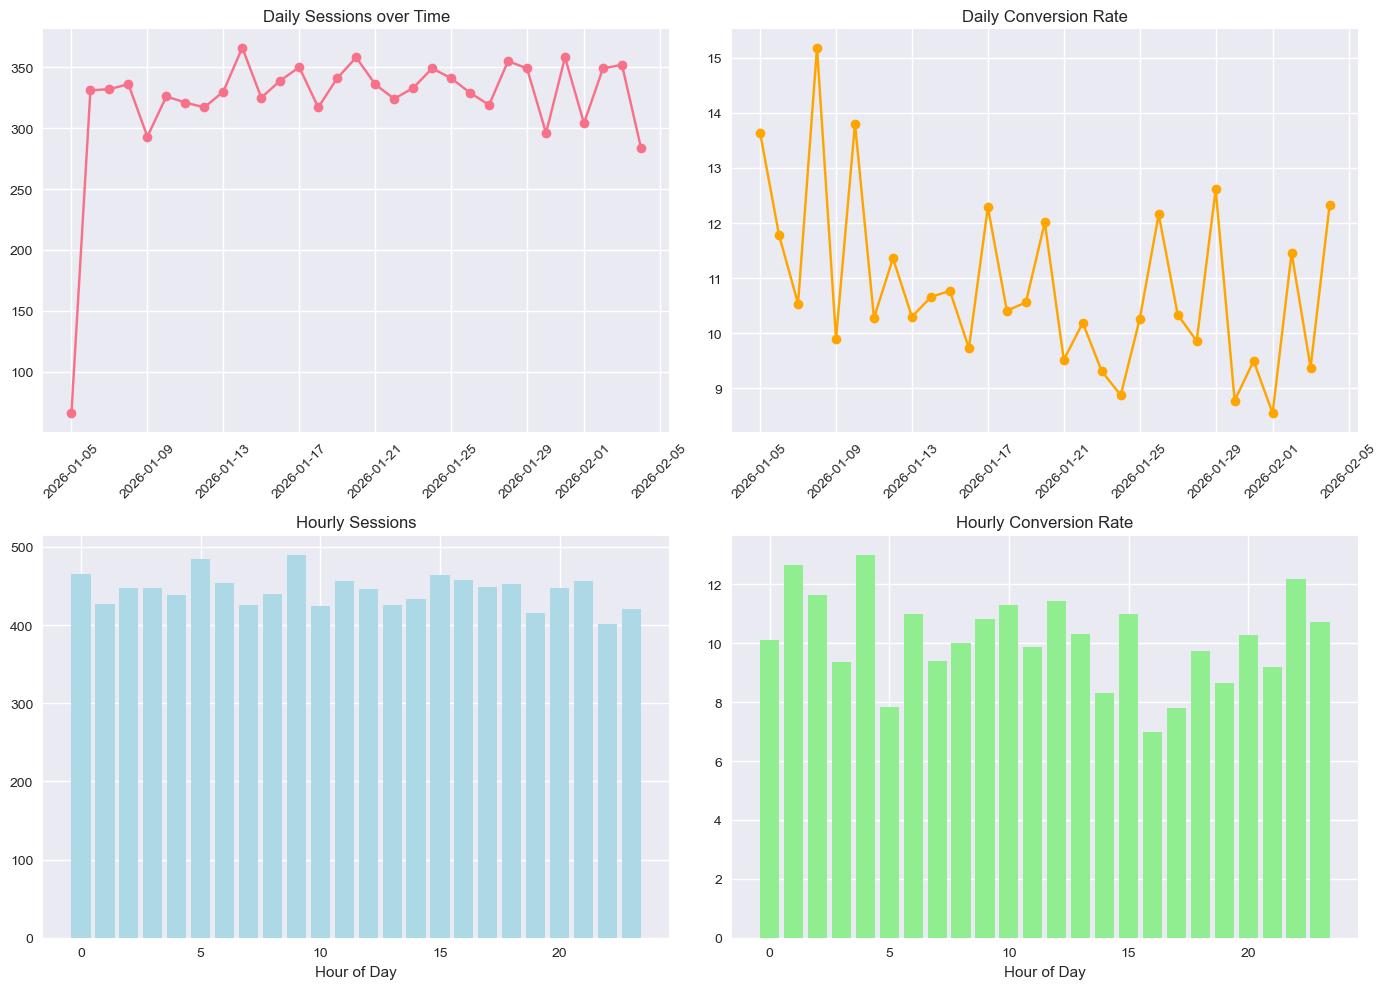

In [51]:
daily_metrics = df.groupby('Date').agg({
    'Session_id': 'nunique',
    'User_id': 'nunique',
    'Revenue': 'sum'
}).rename(columns={
    'Session_id': 'Daily_Sessions',
    'User_id': 'Daily_Users'
})

# Adding Conversion rates daily
daily_conversions = session_summary[session_summary['Max_Funnel_Stage'] == 'Purchase'].groupby(session_summary['Session_start'].dt.date).size()
daily_metrics['Daily_Conversions'] = daily_conversions
daily_metrics['Daily_Conversion_Rate'] = (daily_metrics['Daily_Conversions'] / daily_metrics['Daily_Sessions'] * 100).round(2)

print("Daily Performance Trends: ")
display(daily_metrics.head())

# Hourly patterns
hourly_sessions = df.groupby('Hour').agg({
    'Session_id': 'nunique',
    'Revenue': 'sum'
}).rename(columns={
    'Session_id': 'Hourly_Sessions'
})

hourly_conversions = session_summary[session_summary['Max_Funnel_Stage'] == 'Purchase']
hourly_conversions['Hour'] = hourly_conversions['Session_start'].dt.hour
hourly_conversion_counts = hourly_conversions.groupby('Hour').size()
hourly_sessions['Hourly_Conversions'] = hourly_conversion_counts
hourly_sessions['Hourly_Conversion_Rate'] = (hourly_sessions['Hourly_Conversions'] / hourly_sessions['Hourly_Sessions'] * 100).round(2)


# Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

#Daily sessions
ax1.plot(daily_metrics.index, daily_metrics['Daily_Sessions'], marker='o')
ax1.set_title('Daily Sessions over Time')
ax1.tick_params(axis='x', rotation=45)

# Daily conversion rate
ax2.plot(daily_metrics.index, daily_metrics['Daily_Conversion_Rate'], marker='o', color='orange')
ax2.set_title('Daily Conversion Rate')
ax2.tick_params(axis='x', rotation=45)

# Hourly sessions
ax3.bar(hourly_sessions.index, hourly_sessions['Hourly_Sessions'], color='lightblue')
ax3.set_title('Hourly Sessions')
ax3.set_xlabel('Hour of Day')

# Hourly conversion rate
ax4.bar(hourly_sessions.index, hourly_sessions['Hourly_Conversion_Rate'], color='lightgreen')
ax4.set_title('Hourly Conversion Rate')
ax4.set_xlabel('Hour of Day')

plt.tight_layout()
plt.show()



# Advanced Funnel Metrics and KPIs

In [54]:
print("KEY PERFORMANCE INDICATORS (KPIs): ")
print("="*50)

total_sessions = len(session_summary)
total_revenue = session_summary['Revenue'].sum()
total_orders = len(session_summary[session_summary['Max_Funnel_Stage'] == 'Purchase'])
overall_conversion_rate = (total_orders / total_sessions * 100)

print(f'Total Sessions: {total_sessions:,}')
print(f'Total Revenue: ${total_revenue:,.2f}')
print(f'Total Orders: {total_orders:,}')
print(f'Overall Conversion Rate: {overall_conversion_rate:.2f}%')
print(f"Average Order Value (AOV): ${total_revenue / total_orders:,.2f}")

# Funnel efficiency metrics
browse_to_cart = (funnel_df.iloc[1]['Sessions']/funnel_df.iloc[0]['Sessions'] * 100)
cart_to_checkout = (funnel_df.iloc[2]['Sessions']/funnel_df.iloc[1]['Sessions'] * 100)
checkout_to_purchase = (funnel_df.iloc[3]['Sessions']/funnel_df.iloc[2]['Sessions'] * 100)

print(f"\nStage-to-Stage Conversion Rates:")
print(f"Browse to Add to Cart: {browse_to_cart:.2f}%")
print(f"Add to Cart to Checkout: {cart_to_checkout:.2f}%")
print(f"Checkout to Purchase: {checkout_to_purchase:.2f}%")

# Revenue per session at each stage
revenue_per_browse = total_revenue / funnel_df.iloc[0]['Sessions']
revenue_per_cart = total_revenue / funnel_df.iloc[1]['Sessions']
revenue_per_checkout = total_revenue / funnel_df.iloc[2]['Sessions']

print(f"\nRevenue per Session at Each Stage:")
print(f"Browse: ${revenue_per_browse:.2f}")
print(f"Add to Cart: ${revenue_per_cart:.2f}")
print(f"Checkout: ${revenue_per_checkout:.2f}")


# Bounce rate analysis
bounce_sessions = session_summary[session_summary['Bounce_flag'] == 'Yes']
bounce_rate = (len(bounce_sessions) / total_sessions * 100)
print(f"\nBounce Rate: {bounce_rate:.2f}%")

# Session duration analysis
average_session_duration = session_summary['Session_duration_min'].mean()
print(f"Average Session Duration: {average_session_duration:.2f} minutes")






KEY PERFORMANCE INDICATORS (KPIs): 
Total Sessions: 10,000
Total Revenue: $1,199,366.38
Total Orders: 1,081
Overall Conversion Rate: 10.81%
Average Order Value (AOV): $1,109.50

Stage-to-Stage Conversion Rates:
Browse to Add to Cart: 69.96%
Add to Cart to Checkout: 48.97%
Checkout to Purchase: 31.55%

Revenue per Session at Each Stage:
Browse: $119.94
Add to Cart: $171.44
Checkout: $350.08

Bounce Rate: 89.19%
Average Session Duration: 4.03 minutes


# Strategic Recommendations

In [55]:
print("STRATEGIC RECOMMENDATIONS: ")
print("="*50)

# Identify biggest drop-off points
max_drop_off_stage = funnel_df.loc[funnel_df['Drop_off_rate'].idxmax()]
print(f"Biggest Drop-off Point: {max_drop_off_stage['Stage']} with a drop-off rate of {max_drop_off_stage['Drop_off_rate']:.2f}%")

# Best performing channel
best_channell = channel_df.loc[channel_df['Conversion_Rate'].idxmax()]
print(f"Best Performing Channel: {best_channell['Channel']} with a conversion rate of {best_channell['Conversion_Rate']:.2f}%")

# Best performing region
best_region = regional_analysis.loc[regional_analysis['Conversion_Rate'].idxmax()]
print(f"Best Performing Region: {best_region.name} with a conversion rate of {best_region['Conversion_Rate']:.2f}%")

# Best performing prduct category
best_category = product_analysis.loc[product_analysis['Conversion_Rate'].idxmax()]
print(f"Best Performing Product Category: {best_category.name} with a conversion rate of {best_category['Conversion_Rate']:.2f}%")


print("\n")
print(f"\nRECOMMENDED ACTIONS:")
print(f"1. Optimize the {max_drop_off_stage['Stage']} stage by improving the user experience, simplifying the process, or offering incentives to encourage users to move to the next stage.")
print(f"2. Invest more in the {best_channell['Channel']} channel through targeted marketing campaigns and promotions to capitalize on its high conversion rate.")
print(f"3. Focus on expanding presence and marketing efforts in the {best_region.name} region to leverage its strong performance.")
print(f"4. Highlight and promote products in the {best_category.name} category, as they have the highest conversion rate, potentially through featured placements and special offers.")
print(f"5. Focus on cart abandonment recovery for {funnel_df.iloc[2]['Drop_off_rate']:.2f}% of users dropping off at the checkout stage, by implementing retargeting campaigns and offering incentives to complete purchases.")

# Calculate potential revenue opportunities
cart_abondonment_oppurtunity = funnel_df.iloc[2]['Sessions'] * product_analysis['AOV'].mean()
print(f"\n\nREVENUE OPPORTUNITY")
print(f"Cart Abandonment Recovery: ${cart_abondonment_oppurtunity:,.2f} in potential revenue if we can recover users dropping off at the checkout stage.")




STRATEGIC RECOMMENDATIONS: 
Biggest Drop-off Point: Purchase with a drop-off rate of 68.45%
Best Performing Channel: Email with a conversion rate of 11.30%
Best Performing Region: West with a conversion rate of 11.31%
Best Performing Product Category: Electronics with a conversion rate of 12.15%



RECOMMENDED ACTIONS:
1. Optimize the Purchase stage by improving the user experience, simplifying the process, or offering incentives to encourage users to move to the next stage.
2. Invest more in the Email channel through targeted marketing campaigns and promotions to capitalize on its high conversion rate.
3. Focus on expanding presence and marketing efforts in the West region to leverage its strong performance.
4. Highlight and promote products in the Electronics category, as they have the highest conversion rate, potentially through featured placements and special offers.
5. Focus on cart abandonment recovery for 51.03% of users dropping off at the checkout stage, by implementing retarg

# Export Results

Funnel analysis report exported to 'funnel_analysis_report.xlsx'
Key visualizations saved as 'funnel_conversion_rates.png'


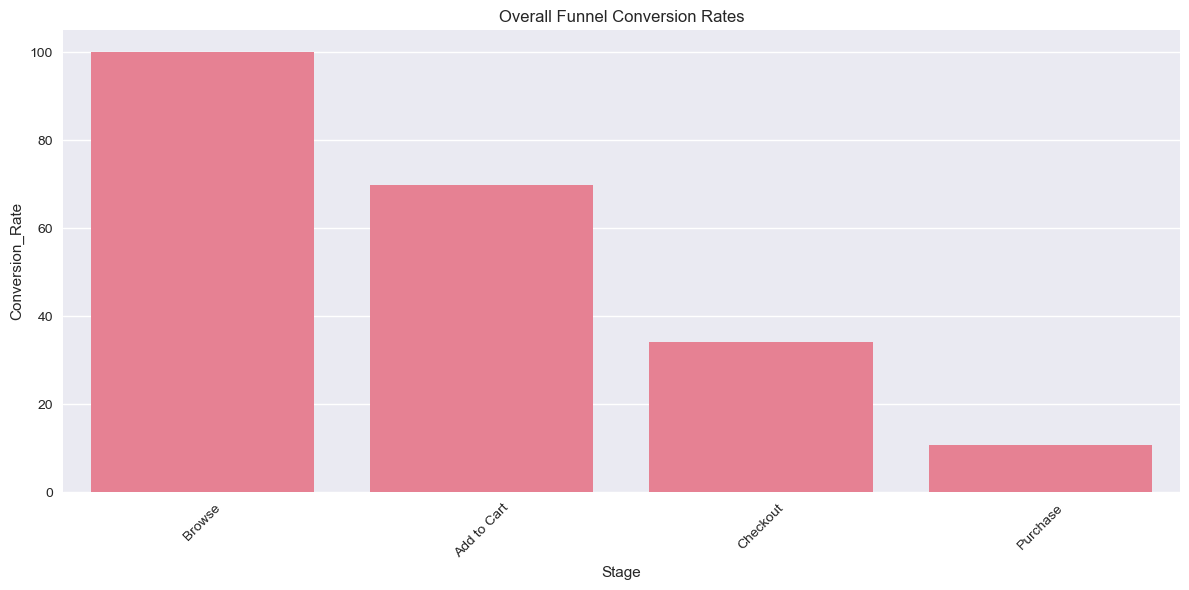

In [58]:
report_data = {
    'Overall_Funnel': funnel_df,
    'Channel_Performance': channel_df,
    'Regional_Analysis': regional_analysis,
    'Device_Performance': device_analysis,
    'Product_Performance': product_analysis,
    'Daily_Trends': daily_metrics,
    'Hourly_Patterns': hourly_sessions
}

# Export to Excel
with pd.ExcelWriter(r'C:\Users\ankus\OneDrive\Desktop\SDE+DATA\DATA\Projects\Funnel_Mechanism (Python_PowerBI)\funnel_analysis_report.xlsx') as writer:
    for sheet_name, data in report_data.items():
        data.to_excel(writer, sheet_name=sheet_name, index=False)

print("Funnel analysis report exported to 'funnel_analysis_report.xlsx'")

# Save Key Visualizations
plt.figure(figsize=(12, 6))
sns.barplot(data=funnel_df, x='Stage', y='Conversion_Rate')
plt.title('Overall Funnel Conversion Rates')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(r'C:\Users\ankus\OneDrive\Desktop\SDE+DATA\DATA\Projects\Funnel_Mechanism (Python_PowerBI)\funnel_conversion_rates.png', dpi=300, bbox_inches='tight')

print("Key visualizations saved as 'funnel_conversion_rates.png'")

